In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('/content/sample_data/dataset_heart.csv')

df.head()


,age,sex,chest pain type,resting blood pressure,serum cholestoral,fasting blood sugar,resting electrocardiographic results,max heart rate,exercise induced angina,oldpeak,ST segment,major vessels,thal,heart disease
0,70,1,4,130,322,0,2,109,0,2.4,2,3,3,2
1,67,0,3,115,564,0,2,160,0,1.6,2,0,7,1
2,57,1,2,124,261,0,0,141,0,0.3,1,0,7,2
3,64,1,4,128,263,0,0,105,1,0.2,2,1,7,1
4,74,0,2,120,269,0,2,121,1,0.2,1,1,3,1


In [3]:
df.tail()

,age,sex,chest pain type,resting blood pressure,serum cholestoral,fasting blood sugar,resting electrocardiographic results,max heart rate,exercise induced angina,oldpeak,ST segment,major vessels,thal,heart disease
265,52,1,3,172,199,1,0,162,0,0.5,1,0,7,1
266,44,1,2,120,263,0,0,173,0,0.0,1,0,7,1
267,56,0,2,140,294,0,2,153,0,1.3,2,0,3,1
268,57,1,4,140,192,0,0,148,0,0.4,2,0,6,1
269,67,1,4,160,286,0,2,108,1,1.5,2,3,3,2


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 14 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   age                                   270 non-null    int64  
 1   sex                                   270 non-null    int64  
 2   chest pain type                       270 non-null    int64  
 3   resting blood pressure                270 non-null    int64  
 4   serum cholestoral                     270 non-null    int64  
 5   fasting blood sugar                   270 non-null    int64  
 6   resting electrocardiographic results  270 non-null    int64  
 7   max heart rate                        270 non-null    int64  
 8   exercise induced angina               270 non-null    int64  
 9   oldpeak                               270 non-null    float64
 10  ST segment                            270 non-null    int64  
 11  major vessels      

In [5]:
df.isnull().sum()

,0
age,0
sex,0
chest pain type,0
resting blood pressure,0
serum cholestoral,0
fasting blood sugar,0
resting electrocardiographic results,0
max heart rate,0
exercise induced angina,0
oldpeak,0


In [7]:
df.describe()

,age,sex,chest pain type,resting blood pressure,serum cholestoral,fasting blood sugar,resting electrocardiographic results,max heart rate,exercise induced angina,oldpeak,ST segment,major vessels,thal,heart disease
count,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.000000,270.00000,270.000000,270.000000,270.000000,270.000000
mean,54.433333,0.677778,3.174074,131.344444,249.659259,0.148148,1.022222,149.677778,0.329630,1.05000,1.585185,0.670370,4.696296,1.444444
std,9.109067,0.468195,0.950090,17.861608,51.686237,0.355906,0.997891,23.165717,0.470952,1.14521,0.614390,0.943896,1.940659,0.497827
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.00000,1.000000,0.000000,3.000000,1.000000
25%,48.000000,0.000000,3.000000,120.000000,213.000000,0.000000,0.000000,133.000000,0.000000,0.00000,1.000000,0.000000,3.000000,1.000000
50%,55.000000,1.000000,3.000000,130.000000,245.000000,0.000000,2.000000,153.500000,0.000000,0.80000,2.000000,0.000000,3.000000,1.000000
75%,61.000000,1.000000,4.000000,140.000000,280.000000,0.000000,2.000000,166.000000,1.000000,1.60000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.20000,3.000000,3.000000,7.000000,2.000000


In [8]:

df['heart disease'].value_counts()


,count
heart disease,
1,150
2,120


In [9]:

df['heart disease'].value_counts(normalize=True) * 100


,proportion
heart disease,
1,55.555556
2,44.444444


In [10]:

X = df.drop('heart disease', axis=1)
y = df['heart disease']

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (270, 13)
Target shape: (270,)


In [11]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (216, 13)
X_test: (54, 13)
y_train: (216,)
y_test: (54,)


In [12]:

from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [13]:

y_pred = model.predict(X_test)

print("Actual values:")
print(y_test.head(10).to_list())

print("\nPredicted values:")
print(y_pred[:10])


Actual values:
[1, 1, 1, 2, 1, 1, 1, 2, 2, 2]

Predicted values:
[1 1 1 2 1 1 1 2 2 2]


In [14]:

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")


Model Accuracy: 79.63 %


In [15]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Confusion Matrix:
[[23  7]
 [ 4 20]]

Classification Report:
              precision    recall  f1-score   support

           1       0.85      0.77      0.81        30
           2       0.74      0.83      0.78        24

    accuracy                           0.80        54
   macro avg       0.80      0.80      0.80        54
weighted avg       0.80      0.80      0.80        54



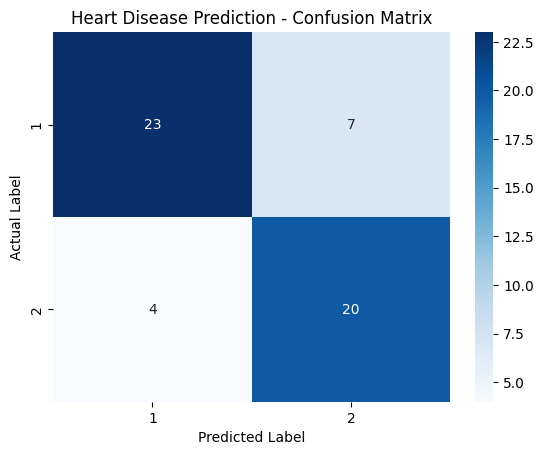

In [16]:
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[1, 2],
    yticklabels=[1, 2]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Heart Disease Prediction - Confusion Matrix")
plt.show()

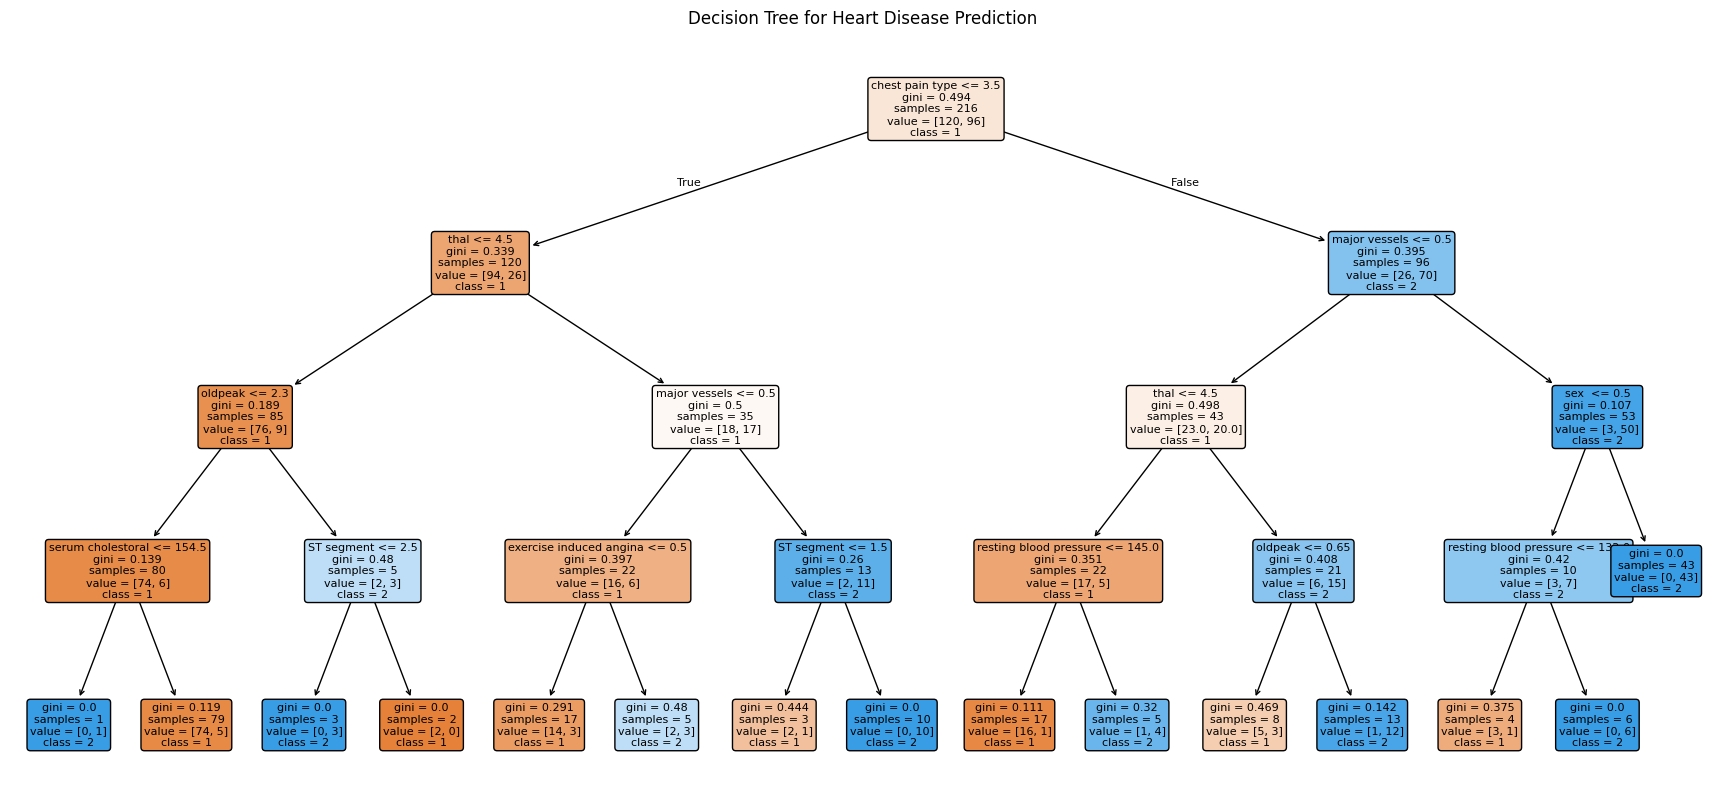

In [17]:

from sklearn.tree import plot_tree

plt.figure(figsize=(22, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree for Heart Disease Prediction")
plt.show()


Confusion Matrix:
[[23  7]
 [ 4 20]]

Classification Report:
              precision    recall  f1-score   support

           1       0.85      0.77      0.81        30
           2       0.74      0.83      0.78        24

    accuracy                           0.80        54
   macro avg       0.80      0.80      0.80        54
weighted avg       0.80      0.80      0.80        54



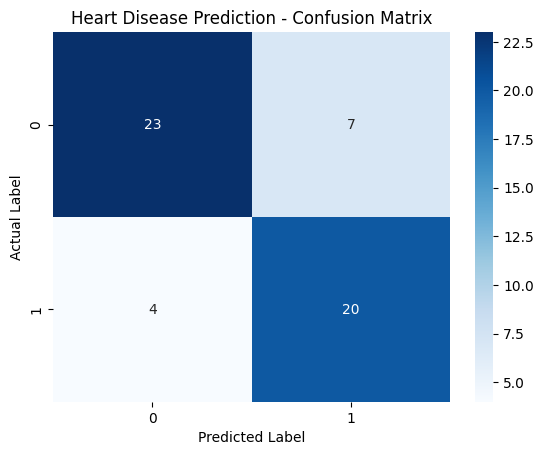

In [18]:

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Heart Disease Prediction - Confusion Matrix")
plt.show()


In [19]:

print(df['heart disease'].value_counts())
print("\nTarget labels:", sorted(df['heart disease'].unique()))


heart disease
1    150
2    120
Name: count, dtype: int64

Target labels: [np.int64(1), np.int64(2)]


In [20]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

depths = [2, 3, 4, 5, 6, 8, 10, None]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for depth in depths:
    tree = DecisionTreeClassifier(
        criterion='gini',
        max_depth=depth,
        random_state=42
    )

    scores = cross_val_score(
        tree, X_train, y_train,
        cv=cv,
        scoring='accuracy'
    )

    print(
        f"Depth: {str(depth):>4} | "
        f"Mean CV Accuracy: {scores.mean() * 100:.2f}%"
    )


Depth:    2 | Mean CV Accuracy: 68.97%
Depth:    3 | Mean CV Accuracy: 71.29%
Depth:    4 | Mean CV Accuracy: 74.55%
Depth:    5 | Mean CV Accuracy: 71.28%
Depth:    6 | Mean CV Accuracy: 73.13%
Depth:    8 | Mean CV Accuracy: 72.19%
Depth:   10 | Mean CV Accuracy: 71.26%
Depth: None | Mean CV Accuracy: 71.26%


In [21]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

best_model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    random_state=42
)

best_model.fit(X_train, y_train)

final_pred = best_model.predict(X_test)

print("Test Accuracy:",
      round(accuracy_score(y_test, final_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, final_pred))


Test Accuracy: 79.63 %

Classification Report:
              precision    recall  f1-score   support

           1       0.85      0.77      0.81        30
           2       0.74      0.83      0.78        24

    accuracy                           0.80        54
   macro avg       0.80      0.80      0.80        54
weighted avg       0.80      0.80      0.80        54



                                 Feature  Importance
2                        chest pain type    0.358974
11                         major vessels    0.208014
12                                  thal    0.156959
3                 resting blood pressure    0.088984
9                                oldpeak    0.071360
10                            ST segment    0.057034
4                      serum cholestoral    0.022204
1                                   sex     0.018712
8                exercise induced angina    0.017760
0                                    age    0.000000
7                         max heart rate    0.000000
5                    fasting blood sugar    0.000000
6   resting electrocardiographic results    0.000000


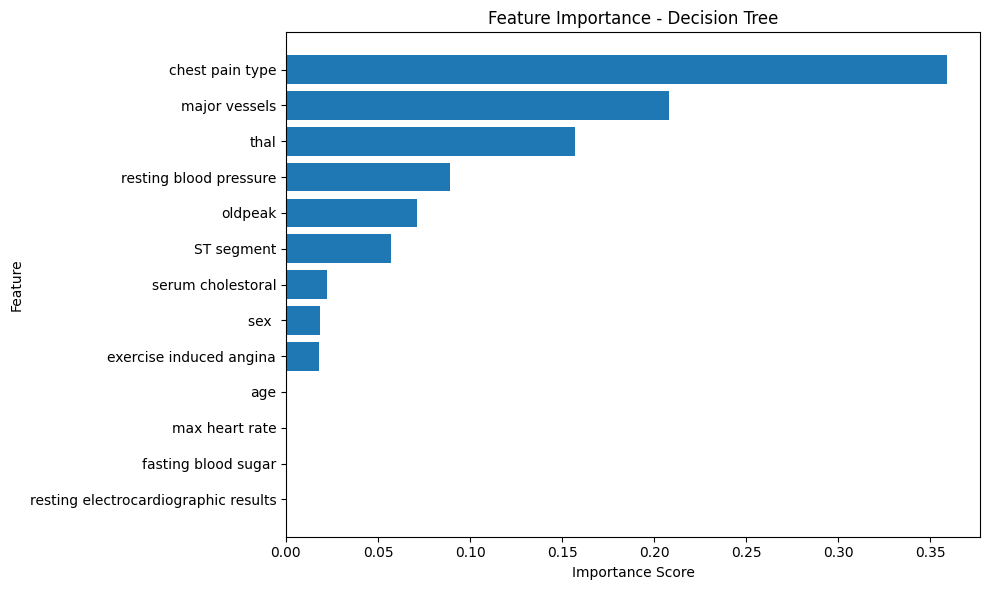

In [22]:

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': best_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

plt.figure(figsize=(10, 6))
plt.barh(importance['Feature'], importance['Importance'])
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.title('Feature Importance - Decision Tree')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [23]:

import joblib

joblib.dump(best_model, 'heart_disease_decision_tree.pkl')

print("Model saved successfully!")


Model saved successfully!
